## LIBs

In [ ]:
import numpy as np 
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

import warnings
warnings.filterwarnings('ignore')

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

## DATA

In [206]:
df = pd.read_csv('titanic.csv')

In [207]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## EDA

In [176]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [177]:
# 5 categorical features --> Encoding

In [178]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [179]:
# Age feature may have Outliers
# Fare feature may have Outliers

In [180]:
df.Pclass.value_counts()

Pclass
3    491
1    216
2    184
Name: count, dtype: int64

In [181]:
df.Parch.value_counts()

Parch
0    678
1    118
2     80
5      5
3      5
4      4
6      1
Name: count, dtype: int64

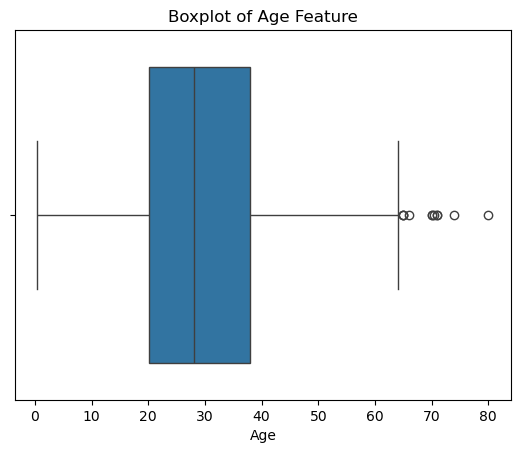

In [182]:
sns.boxplot(x='Age', data=df)
plt.title('Boxplot of Age Feature')
plt.show()

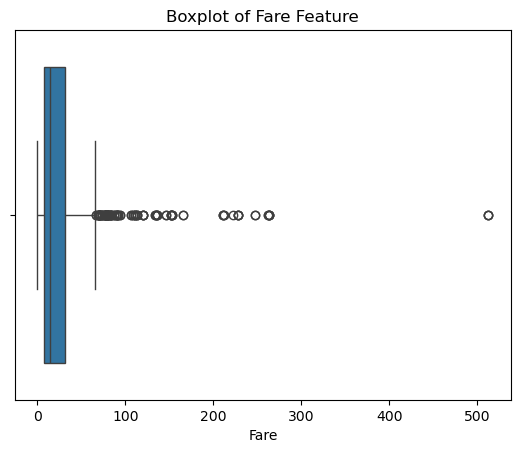

In [183]:
sns.boxplot(x='Fare', data=df)
plt.title('Boxplot of Fare Feature')
plt.show()

In [184]:
len(df)

891

In [185]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [186]:
# Age feature has 177 missing values, we can fill them with the mean or median of the Age feature.
# Cabin feature has 687 missing values, we can drop this feature as it has too many missing values.

In [187]:
df_copy = df.copy()

In [188]:
df_copy.drop(columns=['PassengerId','Name'], inplace=True)

In [189]:
df_copy.duplicated().sum()

15

In [190]:
# drop duplicates if any

In [191]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [192]:
df.Ticket.value_counts()

Ticket
347082      7
CA. 2343    7
1601        7
3101295     6
CA 2144     6
           ..
9234        1
19988       1
2693        1
PC 17612    1
370376      1
Name: count, Length: 681, dtype: int64

In [193]:
df.Survived.value_counts()

Survived
0    549
1    342
Name: count, dtype: int64

<Axes: xlabel='Survived', ylabel='count'>

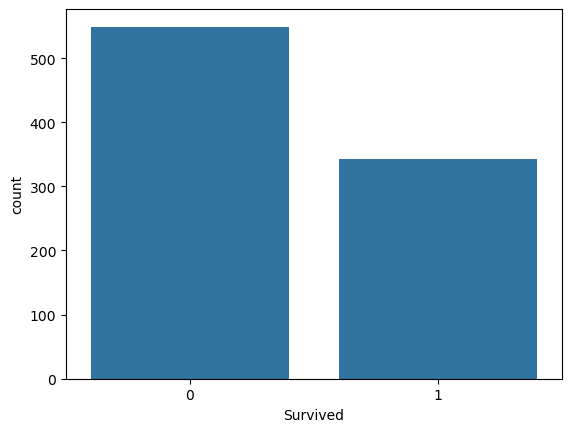

In [194]:
sns.countplot(x='Survived', data=df)

## Preproccessing

### T1

#### 01 Feature Selection

In [208]:
df_copy= df.copy()

In [209]:
df_copy.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [455]:
df.SibSp.value_counts()

SibSp
0    608
1    209
2     28
4     18
3     16
8      7
5      5
Name: count, dtype: int64

In [210]:
df_copy.drop(columns=['PassengerId','Name','Ticket','Cabin'], inplace=True)

In [211]:
df_copy.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,male,22.0,1,0,7.2500,S
1,1,1,female,38.0,1,0,71.2833,C
2,1,3,female,26.0,0,0,7.9250,S
3,1,1,female,35.0,1,0,53.1000,S
4,0,3,male,35.0,0,0,8.0500,S


#### 02 Handle Dup

In [212]:
df_copy.duplicated().sum()

111

In [213]:
df_copy.drop_duplicates(inplace=True)

In [214]:
df_copy.duplicated().sum()

0

#### 03 Splitting

In [215]:
x = df_copy.drop(columns=['Survived'])
y = df_copy['Survived']

In [216]:
x_train, x_test, y_train, y_test = train_test_split(x,y,
                                                    test_size=0.2,
                                                    random_state=42,
                                                    stratify=y)

In [217]:
print(f'x_train = {x_train.shape}')
print(f'y_train = {y_train.shape}')
print(f'---'*10)
print(f'x_test = {x_test.shape}')
print(f'y_test = {y_test.shape}')


x_train = (624, 7)
y_train = (624,)
------------------------------
x_test = (156, 7)
y_test = (156,)


#### 04 Handle Nulls

In [219]:
x_train.isnull().sum()

Pclass       0
Sex          0
Age         83
SibSp        0
Parch        0
Fare         0
Embarked     2
dtype: int64

In [220]:
x_train.Embarked.fillna(x_train.Embarked.mode()[0], inplace=True)

In [221]:
x_train.isnull().sum()

Pclass       0
Sex          0
Age         83
SibSp        0
Parch        0
Fare         0
Embarked     0
dtype: int64

In [222]:
x_test.isnull().sum()

Pclass       0
Sex          0
Age         21
SibSp        0
Parch        0
Fare         0
Embarked     0
dtype: int64

In [223]:
df.Pclass.value_counts()

Pclass
3    491
1    216
2    184
Name: count, dtype: int64

<Axes: xlabel='Pclass', ylabel='Age'>

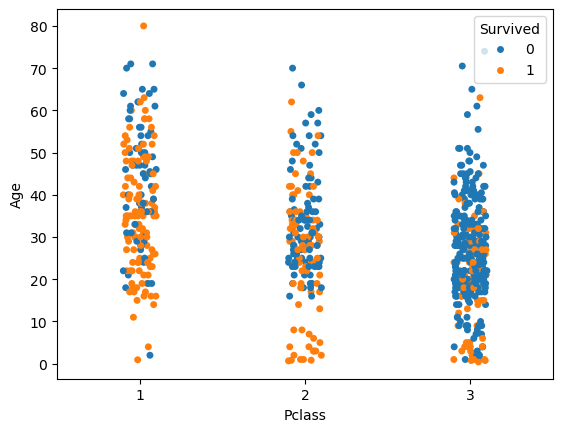

In [224]:
sns.stripplot(x='Pclass', y='Age', data=df,hue='Survived' ,jitter=True)

In [225]:
median_age_by_class = x_train.groupby('Pclass')['Age'].median()

In [226]:
median_age_by_class

Pclass
1    37.0
2    29.0
3    24.0
Name: Age, dtype: float64

In [227]:
x_train.shape

(624, 7)

In [228]:
y_train.shape

(624,)

In [229]:
for pclass in median_age_by_class.index:
    x_train.loc[(x_train['Pclass'] == pclass) & (x_train['Age'].isnull()), 'Age'] = median_age_by_class[pclass]
    x_test.loc[(x_test['Pclass'] == pclass) & (x_test['Age'].isnull()), 'Age'] = median_age_by_class[pclass]

In [230]:
x_train.isnull().sum()

Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    0
dtype: int64

In [231]:
x_test.isnull().sum()

Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    0
dtype: int64

#### 05 Outliers

In [ ]:
# Age feature has outliers, It is acceptable to keep them as they are, 
# as they may represent real passengers with extreme ages. We will not remove them.

<Axes: xlabel='Fare'>

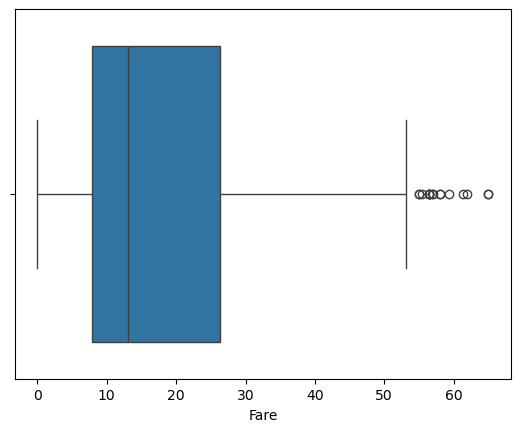

In [151]:
sns.boxplot(x='Fare', data=x_train)

In [ ]:
Q1 = x_train['Fare'].quantile(0.25)
Q3 = x_train['Fare'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

mask = (x_train['Fare'] >= lower_bound) & (x_train['Fare'] <= upper_bound)

#remove outliers from Fare feature
x_train = x_train.loc[mask]
y_train = y_train.loc[mask]

In [233]:
x_train.shape

(548, 7)

In [234]:
y_train.shape

(548,)

In [154]:
y_train

710    1
830    1
114    0
652    0
624    0
      ..
203    0
766    0
347    1
58     1
89     0
Name: Survived, Length: 624, dtype: int64

<Axes: xlabel='Fare'>

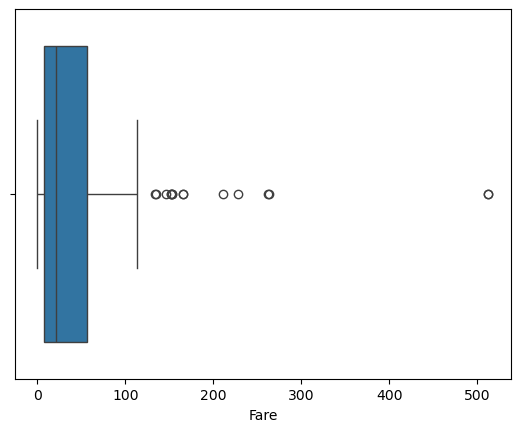

In [155]:
sns.boxplot(x='Fare', data=x_test)

#### 06 Encodeing

In [235]:
x_train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 548 entries, 710 to 89
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Pclass    548 non-null    int64  
 1   Sex       548 non-null    object 
 2   Age       548 non-null    float64
 3   SibSp     548 non-null    int64  
 4   Parch     548 non-null    int64  
 5   Fare      548 non-null    float64
 6   Embarked  548 non-null    object 
dtypes: float64(2), int64(3), object(2)
memory usage: 34.2+ KB


In [236]:
x_train.Embarked.value_counts

<bound method IndexOpsMixin.value_counts of 710    C
830    C
114    C
652    S
624    S
      ..
203    C
766    C
347    S
58     S
89     S
Name: Embarked, Length: 548, dtype: object>

In [237]:
x_train_dummies = pd.get_dummies(x_train, columns=['Sex','Embarked'], drop_first=True)
x_test_dummies = pd.get_dummies(x_test, columns=['Sex','Embarked'], drop_first=True)

In [238]:
x_train_dummies.info()

<class 'pandas.core.frame.DataFrame'>
Index: 548 entries, 710 to 89
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Pclass      548 non-null    int64  
 1   Age         548 non-null    float64
 2   SibSp       548 non-null    int64  
 3   Parch       548 non-null    int64  
 4   Fare        548 non-null    float64
 5   Sex_male    548 non-null    bool   
 6   Embarked_Q  548 non-null    bool   
 7   Embarked_S  548 non-null    bool   
dtypes: bool(3), float64(2), int64(3)
memory usage: 27.3 KB


In [239]:
x_train_dummies.head()

,Pclass,Age,SibSp,Parch,Fare,Sex_male,Embarked_Q,Embarked_S
710,1,24.0,0,0,49.5042,False,False,False
830,3,15.0,1,0,14.4542,False,False,False
114,3,17.0,0,0,14.4583,False,False,False
652,3,21.0,0,0,8.4333,True,False,True
624,3,21.0,0,0,16.1000,True,False,True


#### 07 Scaling

In [240]:
x_train_dummies.head()

,Pclass,Age,SibSp,Parch,Fare,Sex_male,Embarked_Q,Embarked_S
710,1,24.0,0,0,49.5042,False,False,False
830,3,15.0,1,0,14.4542,False,False,False
114,3,17.0,0,0,14.4583,False,False,False
652,3,21.0,0,0,8.4333,True,False,True
624,3,21.0,0,0,16.1000,True,False,True


In [241]:
from sklearn.preprocessing import RobustScaler

In [242]:
scaler = RobustScaler()

In [243]:
x_train_dummies[['Fare', 'Age']] = scaler.fit_transform(x_train_dummies[['Fare', 'Age']])
x_test_dummies[['Fare', 'Age']] = scaler.transform(x_test_dummies[['Fare', 'Age']])

In [244]:
x_train_dummies.head()

,Pclass,Age,SibSp,Parch,Fare,Sex_male,Embarked_Q,Embarked_S
710,1,-0.132231,0,0,1.987973,False,False,False
830,3,-0.727273,1,0,0.079194,False,False,False
114,3,-0.595041,0,0,0.079417,False,False,False
652,3,-0.330579,0,0,-0.248697,True,False,True
624,3,-0.330579,0,0,0.168822,True,False,True


### T2

#### 01 Feature Selection

In [418]:
df_copy2= df.copy()

In [419]:
df_copy2.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [420]:
df_copy2.drop(columns=['PassengerId','Name','Ticket','Cabin'], inplace=True)

In [421]:
df_copy2.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,male,22.0,1,0,7.2500,S
1,1,1,female,38.0,1,0,71.2833,C
2,1,3,female,26.0,0,0,7.9250,S
3,1,1,female,35.0,1,0,53.1000,S
4,0,3,male,35.0,0,0,8.0500,S


#### 03 Splitting

In [422]:
x2 = df_copy2.drop(columns=['Survived'])
y2 = df_copy2['Survived']

In [423]:
x_train2, x_test2, y_train2, y_test2 = train_test_split(x2,y2,
                                                    test_size=0.2,
                                                    random_state=42,
                                                    stratify=y2)

In [424]:
print(f'x_train = {x_train2.shape}')
print(f'y_train = {y_train2.shape}')
print(f'---'*10)
print(f'x_test = {x_test2.shape}')
print(f'y_test = {y_test2.shape}')


x_train = (712, 7)
y_train = (712,)
------------------------------
x_test = (179, 7)
y_test = (179,)


#### 04 Handle Nulls

In [425]:
x_train2.isnull().sum()

Pclass        0
Sex           0
Age         137
SibSp         0
Parch         0
Fare          0
Embarked      2
dtype: int64

In [426]:
x_train2.Embarked.fillna(x_train2.Embarked.mode()[0], inplace=True)

In [427]:
x_train2.isnull().sum()

Pclass        0
Sex           0
Age         137
SibSp         0
Parch         0
Fare          0
Embarked      0
dtype: int64

In [428]:
x_test2.isnull().sum()

Pclass       0
Sex          0
Age         40
SibSp        0
Parch        0
Fare         0
Embarked     0
dtype: int64

In [429]:
df_copy2.Pclass.value_counts()

Pclass
3    491
1    216
2    184
Name: count, dtype: int64

<Axes: xlabel='Pclass', ylabel='Age'>

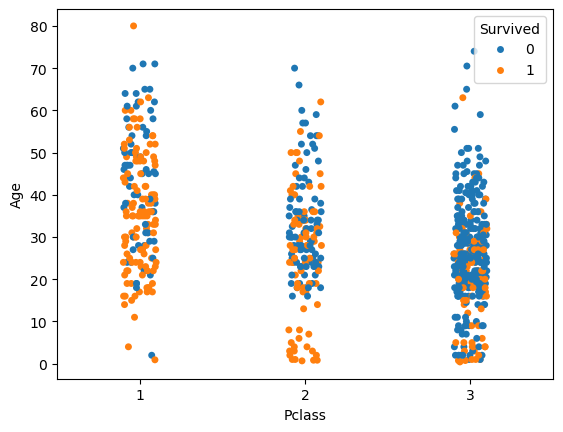

In [430]:
sns.stripplot(x='Pclass', y='Age', data=df_copy2,hue='Survived' ,jitter=True)

In [431]:
median_age_by_class = x_train2.groupby('Pclass')['Age'].median()

In [432]:
median_age_by_class

Pclass
1    38.0
2    29.0
3    24.0
Name: Age, dtype: float64

In [433]:
x_train.shape

(548, 7)

In [434]:
y_train.shape

(548,)

In [435]:
for pclass in median_age_by_class.index:
    x_train2.loc[(x_train2['Pclass'] == pclass) & (x_train2['Age'].isnull()), 'Age'] = median_age_by_class[pclass]
    x_test2.loc[(x_test2['Pclass'] == pclass) & (x_test2['Age'].isnull()), 'Age'] = median_age_by_class[pclass]

In [436]:
x_train2.isnull().sum()

Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    0
dtype: int64

In [437]:
x_test2.isnull().sum()

Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    0
dtype: int64

#### 06 Encodeing

In [438]:
x_train2.info()

<class 'pandas.core.frame.DataFrame'>
Index: 712 entries, 692 to 507
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Pclass    712 non-null    int64  
 1   Sex       712 non-null    object 
 2   Age       712 non-null    float64
 3   SibSp     712 non-null    int64  
 4   Parch     712 non-null    int64  
 5   Fare      712 non-null    float64
 6   Embarked  712 non-null    object 
dtypes: float64(2), int64(3), object(2)
memory usage: 44.5+ KB


In [439]:
x_train2.Embarked.value_counts()

Embarked
S    518
C    139
Q     55
Name: count, dtype: int64

In [440]:
x_train_dummies2    = pd.get_dummies(x_train2, columns=['Sex','Embarked'], drop_first=True)
x_test_dummies2     = pd.get_dummies(x_test2, columns=['Sex','Embarked'], drop_first=True)

In [441]:
x_train_dummies2.info()

<class 'pandas.core.frame.DataFrame'>
Index: 712 entries, 692 to 507
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Pclass      712 non-null    int64  
 1   Age         712 non-null    float64
 2   SibSp       712 non-null    int64  
 3   Parch       712 non-null    int64  
 4   Fare        712 non-null    float64
 5   Sex_male    712 non-null    bool   
 6   Embarked_Q  712 non-null    bool   
 7   Embarked_S  712 non-null    bool   
dtypes: bool(3), float64(2), int64(3)
memory usage: 35.5 KB


In [442]:
x_train_dummies2.head()

,Pclass,Age,SibSp,Parch,Fare,Sex_male,Embarked_Q,Embarked_S
692,3,24.0,0,0,56.4958,True,False,True
481,2,29.0,0,0,0.0000,True,False,True
527,1,38.0,0,0,221.7792,True,False,True
855,3,18.0,0,1,9.3500,False,False,True
801,2,31.0,1,1,26.2500,False,False,True


#### 07 Scaling

In [443]:
x_train_dummies2.head()

,Pclass,Age,SibSp,Parch,Fare,Sex_male,Embarked_Q,Embarked_S
692,3,24.0,0,0,56.4958,True,False,True
481,2,29.0,0,0,0.0000,True,False,True
527,1,38.0,0,0,221.7792,True,False,True
855,3,18.0,0,1,9.3500,False,False,True
801,2,31.0,1,1,26.2500,False,False,True


In [444]:
from sklearn.preprocessing import RobustScaler

In [445]:
scaler = RobustScaler()

In [446]:
x_train_dummies2[['Fare', 'Age']] = scaler.fit_transform(x_train_dummies2[['Fare', 'Age']])
x_test_dummies2[['Fare', 'Age']] = scaler.transform(x_test_dummies2[['Fare', 'Age']])

In [447]:
x_train_dummies2.head()

,Pclass,Age,SibSp,Parch,Fare,Sex_male,Embarked_Q,Embarked_S
692,3,-0.1875,0,0,1.819652,True,False,True
481,2,0.1250,0,0,-0.625609,True,False,True
527,1,0.6875,0,0,8.973477,True,False,True
855,3,-0.5625,0,1,-0.220921,False,False,True
801,2,0.2500,1,1,0.510548,False,False,True


## Classification

### T1

In [252]:
from sklearn.linear_model import LogisticRegression

In [253]:
LR1 = LogisticRegression()

In [254]:
LR1.fit(x_train_dummies, y_train)

LogisticRegression()

In [255]:
y_pred1 = LR1.predict(x_test_dummies)

In [256]:
from sklearn.metrics import accuracy_score

In [257]:
accuracy_score(y_test, y_pred1)

0.7692307692307693

### T2

In [448]:
from sklearn.linear_model import LogisticRegression

In [449]:
LR2 = LogisticRegression()

In [450]:
LR2.fit(x_train_dummies2, y_train2)

LogisticRegression()

In [451]:
y_pred1 = LR2.predict(x_test_dummies2)   

In [452]:
from sklearn.metrics import accuracy_score

In [453]:
accuracy_score(y_test2, y_pred1)

0.8156424581005587